In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
print("training data", train.shape)
print("testing data", test.shape)
train.head()

training data (1460, 81)
testing data (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [2]:
missing = test.isnull().sum()
missing[missing > 0].sort_values(ascending=False)

,0
PoolQC,1456
MiscFeature,1408
Alley,1352
Fence,1169
MasVnrType,894
FireplaceQu,730
LotFrontage,227
GarageQual,78
GarageCond,78
GarageYrBlt,78


In [3]:
missing = train.isnull().sum()

missing[missing > 0].sort_values(ascending=False)

,0
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
MasVnrType,872
FireplaceQu,690
LotFrontage,259
GarageType,81
GarageYrBlt,81
GarageFinish,81


In [4]:
print("total columns:", train.shape[1])
print("columns with missing values:", (train.isnull().sum() > 0).sum())
print("columns without missing values", (train.isnull().sum() == 0).sum())

total columns: 81
columns with missing values: 19
columns without missing values 62


In [5]:
print("total columns", test.shape[1])
print("columns with null", (test.isnull().sum() > 0).sum())
print("columns without null", (test.isnull().sum() == 0).sum())

total columns 80
columns with null 33
columns without null 47


In [6]:
train_missing = train.isnull().sum()
test_missing = test.isnull().sum()

missing_summary = pd.DataFrame({
    "Train Missing": train_missing,
    "Test Missing": test_missing
})

missing_summary = missing_summary[
    (missing_summary["Train Missing"] > 0) |
    (missing_summary["Test Missing"] > 0)
]

missing_summary.sort_values(
    by="Train Missing",
    ascending=False
)

,Train Missing,Test Missing
PoolQC,1453,1456.0
MiscFeature,1406,1408.0
Alley,1369,1352.0
Fence,1179,1169.0
MasVnrType,872,894.0
FireplaceQu,690,730.0
LotFrontage,259,227.0
GarageFinish,81,78.0
GarageCond,81,78.0
GarageYrBlt,81,78.0


In [7]:
none_columns =[
    "PoolQC", "MiscFeature", "Alley", "Fence",
    "MasVnrType", "FireplaceQu", "GarageType",
    "GarageFinish", "GarageQual", "GarageCond",
    "BsmtExposure", "BsmtFinType2", "BsmtQual",
    "BsmtCond", "BsmtFinType1"
]

for col in none_columns:
  train[col] = train[col].fillna("none")
  test[col] = test[col].fillna("none")

In [8]:
numeric_columns = ["LotFrontage", "MasVnrArea", "GarageYrBlt"]

for col in numeric_columns:
  train[col] = train[col].fillna(train[col].median())
  test[col] = test[col].fillna(train[col].median())

In [9]:
train["Electrical"] = train["Electrical"].mode()[0]

In [10]:
train["Electrical"] = train["Electrical"].fillna(
    train["Electrical"].mode()[0]
)

test["MSZoning"] = test["MSZoning"].fillna(
    train["MSZoning"].mode()[0]
)

test["Utilities"] = test["Utilities"].fillna(
    train["Utilities"].mode()[0]
)

test["Exterior1st"] = test["Exterior1st"].fillna(
    train["Exterior1st"].mode()[0]
)

test["Exterior2nd"] = test["Exterior2nd"].fillna(
    train["Exterior2nd"].mode()[0]
)

test["KitchenQual"] = test["KitchenQual"].fillna(
    train["KitchenQual"].mode()[0]
)

test["Functional"] = test["Functional"].fillna(
    train["Functional"].mode()[0]
)

test["SaleType"] = test["SaleType"].fillna(
    train["SaleType"].mode()[0]
)

In [11]:
print("Remaining missing cells in train:", train.isnull().sum().sum())
print("Remaining missing cells in test:", test.isnull().sum().sum())

Remaining missing cells in train: 0
Remaining missing cells in test: 10


In [12]:
print("\nTest missing columns:")
print(test.isnull().sum()[test.isnull().sum() > 0])


Test missing columns:
BsmtFinSF1      1
BsmtFinSF2      1
BsmtUnfSF       1
TotalBsmtSF     1
BsmtFullBath    2
BsmtHalfBath    2
GarageCars      1
GarageArea      1
dtype: int64


In [13]:
# Fill numerical missing values using training medians
numeric_test_cols = [
    "BsmtFinSF1",
    "BsmtFinSF2",
    "BsmtUnfSF",
    "TotalBsmtSF",
    "BsmtFullBath",
    "BsmtHalfBath",
    "GarageCars",
    "GarageArea"
]

for col in numeric_test_cols:
    test[col] = test[col].fillna(train[col].median())

In [14]:
print("Missing cells in train:", train.isnull().sum().sum())
print("Missing cells in test:", test.isnull().sum().sum())

Missing cells in train: 0
Missing cells in test: 0


In [15]:
print("house area" in train.columns)

False


In [16]:
x = train.drop("SalePrice", axis=1)
y = train["SalePrice"]

print("feauture shape:", x.shape)
print("target shape", y.shape)

feauture shape: (1460, 80)
target shape (1460,)


In [17]:
categorical_cols = x.select_dtypes(include=["object"]).columns

In [18]:
print("Number of categorical columns:", len(categorical_cols))

Number of categorical columns: 43


In [19]:
print(categorical_cols.tolist())

['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition']


In [20]:
all_features = pd.concat([x, test], axis=0)

In [21]:
all_features = pd.get_dummies(all_features, dummy_na=False)

In [22]:
X = all_features.iloc[:len(train), :]
test_features = all_features.iloc[len(train):, :]

In [23]:
print("Training features:", X.shape)
print("Test features:", test_features.shape)
print("Same columns:", X.columns.equals(test_features.columns))

Training features: (1460, 302)
Test features: (1459, 302)
Same columns: True


In [24]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("y_train:", y_train.shape)
print("y_val:", y_val.shape)

X_train: (1168, 302)
X_val: (292, 302)
y_train: (1168,)
y_val: (292,)


In [25]:
from sklearn.linear_model import LinearRegression

# Create the model
model = LinearRegression()

# Train the model using training data
model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [26]:
# Predict prices for validation data
y_pred = model.predict(X_val)

# Display actual and predicted prices
results = pd.DataFrame({
    "Actual Price": y_val.values,
    "Predicted Price": y_pred
})

print(results.head(10))

   Actual Price  Predicted Price
0        154500    160290.519495
1        325000    342927.654676
2        115000     88377.297238
3        159000    176579.480335
4        315500    321419.413964
5         75500     68008.595048
6        311500    239371.797171
7        146000    146954.729915
8         84500     62984.638444
9        135500    151849.666549


In [27]:
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

# Calculate R² score
r2 = r2_score(y_val, y_pred)

# Calculate Mean Squared Error
mse = mean_squared_error(y_val, y_pred)

# Calculate Root Mean Squared Error
rmse = np.sqrt(mse)

print("R² Score:", round(r2, 4))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))

R² Score: 0.4411
MSE: 4286876422.84
RMSE: 65474.24


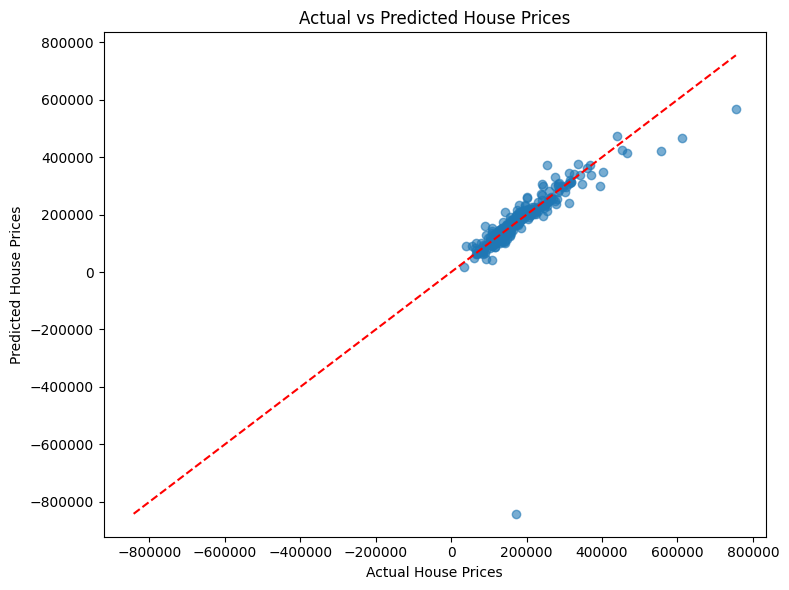

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_val, y_pred, alpha=0.6)

# Ideal prediction line
min_price = min(y_val.min(), y_pred.min())
max_price = max(y_val.max(), y_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    color="red",
    linestyle="--"
)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted House Prices")
plt.tight_layout()
plt.show()

In [29]:
# Compare actual and predicted prices
results = pd.DataFrame({
    "Actual Price": y_val,
    "Predicted Price": y_pred
})

results["Absolute Error"] = abs(
    results["Actual Price"] - results["Predicted Price"]
)

# Show the 10 largest errors
print(
    results.sort_values(
        by="Absolute Error", ascending=False
    ).head(10)
)

      Actual Price  Predicted Price  Absolute Error
1170        171000   -842042.336469    1.013042e+06
691         755000    567647.909014    1.873521e+05
898         611657    468364.029755    1.432930e+05
1046        556581    420979.630659    1.356014e+05
581         253293    372387.653940    1.190947e+05
774         395000    300561.265061    9.443873e+04
218         311500    239371.797171    7.212820e+04
479          89471    159616.495074    7.014550e+04
271         241500    308104.495934    6.660450e+04
693         108480     42101.299574    6.637870e+04


In [30]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

# Transform training prices using log(1 + price)
y_train_log = np.log1p(y_train)

# Train a new model
model_log = LinearRegression()
model_log.fit(X_train, y_train_log)

# Predict and convert back to normal prices
y_pred_log = model_log.predict(X_val)
y_pred_improved = np.expm1(y_pred_log)

# Evaluate the improved model
r2_improved = r2_score(y_val, y_pred_improved)
rmse_improved = np.sqrt(
    mean_squared_error(y_val, y_pred_improved)
)

print("Improved R² Score:", round(r2_improved, 4))
print("Improved RMSE:", round(rmse_improved, 2))
print("Minimum predicted price:", round(y_pred_improved.min(), 2))

Improved R² Score: 0.9319
Improved RMSE: 22861.19
Minimum predicted price: 43143.36


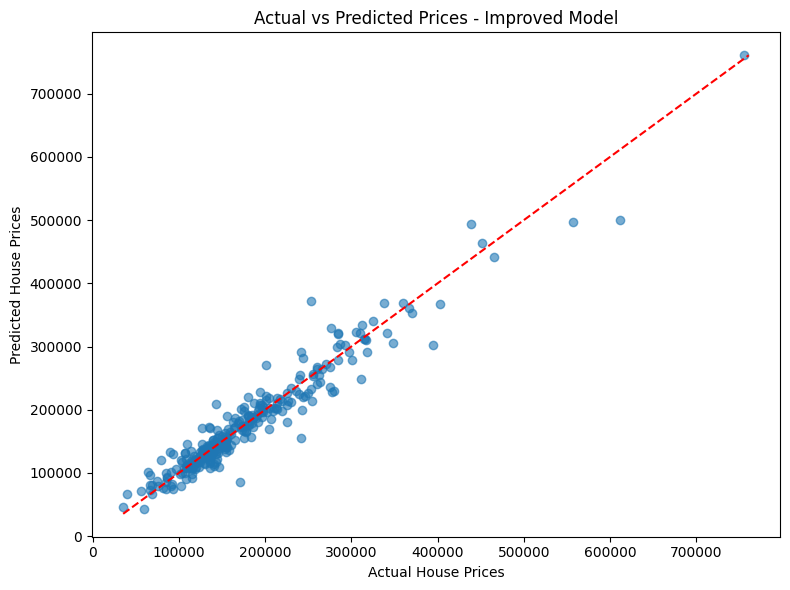

In [31]:
plt.figure(figsize=(8, 6))

plt.scatter(y_val, y_pred_improved, alpha=0.6)

min_price = min(y_val.min(), y_pred_improved.min())
max_price = max(y_val.max(), y_pred_improved.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    "r--"
)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted Prices - Improved Model")
plt.tight_layout()
plt.show()

In [32]:
# Transform all training prices
y_log = np.log1p(y)

# Create and train the final model
final_model = LinearRegression()
final_model.fit(X, y_log)

print("Final model trained on all training data!")

Final model trained on all training data!


In [33]:
# Predict log prices for the test dataset
test_predictions_log = final_model.predict(test_features)

# Convert predictions back to normal prices
test_predictions = np.expm1(test_predictions_log)

print("Number of predictions:", len(test_predictions))
print("First 10 predicted prices:")
print(test_predictions[:10])

Number of predictions: 1459
First 10 predicted prices:
[121289.24483435 165747.76108124 181988.93383844 202404.41043563
 192897.29856116 170748.19914946 177833.75427578 162377.32813256
 195501.2640217  119749.47930161]


In [34]:
# Create the Kaggle submission file
submission = pd.DataFrame({
    "Id": test["Id"],
    "SalePrice": test_predictions
})

submission.to_csv("submission.csv", index=False)

print("Submission file created successfully!")
print(submission.head())
print("Submission shape:", submission.shape)

Submission file created successfully!
     Id      SalePrice
0  1461  121289.244834
1  1462  165747.761081
2  1463  181988.933838
3  1464  202404.410436
4  1465  192897.298561
Submission shape: (1459, 2)


In [35]:
from google.colab import files
files.download("submission.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>